# compresskit — original vs compressed, side by side

One image, both models, in one process. The point is to make the trade-off
concrete: the compressed model is several times smaller and faster, and you can
see for yourself whether it still gets the answer right.

Run `experiments/train_baseline.py` first to produce a checkpoint.

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, "..")

import numpy as np
import matplotlib.pyplot as plt
import torch

from compresskit.benchmark import benchmark, make_session
from compresskit.data import CIFAR10_MEAN, CIFAR10_STD, calibration_loader, test_loader
from compresskit.export import size_mb, to_onnx
from compresskit.host import probe
from compresskit.pipeline import Pipeline
from compresskit.train import load_model

CLASSES = ["airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck"]

print(probe().describe())

host      : Apple M5 (arm64, Darwin)
cores     : 10 logical / 4 performance
ISA       : bf16, dotprod, fp16, i8mm, neon
INT8      : fast — INT8 has fused kernels here (i8mm, dotprod) — expect a real latency win.
default   : int8
versions  : python 3.14.6, torch 2.14.0, onnxruntime 1.29.0, numpy 2.5.2


## 1. Load the baseline

This is both the accuracy reference and the distillation teacher.

In [2]:
CHECKPOINT = "../checkpoints/resnet20_fp32.pt"

model, meta = load_model(CHECKPOINT)
print(f"{meta['arch']}: {meta['accuracy'] * 100:.2f}% top-1 on the test split")
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")

resnet20: 91.54% top-1 on the test split
272,474 parameters


## 2. Compress it

Prune 50% of channels (SIMD-aligned), re-estimate BatchNorm, then quantize to
INT8. Quantization runs last because it changes weight dtype, which would break
pruning and block fine-tuning.

In [3]:
calib = calibration_loader(n=512, batch_size=64)
test = test_loader(batch_size=256)

pipe = (Pipeline(model, calib, test, workdir="../artifacts/demo")
        .prune(ratio=0.5, align=16)
        .recover()
        .quantize(precision="auto"))

print(pipe.preflight())
result = pipe.run()

PRE-FLIGHT
host      : Apple M5 (arm64, Darwin)
cores     : 10 logical / 4 performance
ISA       : bf16, dotprod, fp16, i8mm, neon
INT8      : fast — INT8 has fused kernels here (i8mm, dotprod) — expect a real latency win.
default   : int8
versions  : python 3.14.6, torch 2.14.0, onnxruntime 1.29.0, numpy 2.5.2

model     : 272,474 parameters, input (1, 3, 32, 32)
calibration: 512 samples (must come from the train split)
protected : classifier ['Linear'] is never pruned
plan      : prune -> recover -> quantize
baseline               fp32  acc  91.54%  lat   0.881 ms (p95   0.930)  size   1.05 MB  params 272,474
  params 272,474 -> 80,762 (70.4% removed)  MACs 41.2M -> 21.8M (47.1% removed)
1_prune                fp32  acc  10.06%  lat   0.638 ms (p95   0.664)  size   0.32 MB  params 80,762
2_recover              fp32  acc  22.44%  lat   0.637 ms (p95   0.663)  size   0.32 MB  params 80,762
  int8 artifact: 3_quantize.onnx (0.13 MB)
  quantized 22/22 compute ops (100%)
  ! precision aut

In [4]:
print(result.summary())

baseline               fp32  acc  91.54%  lat   0.881 ms (p95   0.930)  size   1.05 MB  params 272,474
------------------------------------------------------------------------------------------------------
1_prune                fp32  acc  10.06%  lat   0.638 ms (p95   0.664)  size   0.32 MB  params 80,762
2_recover              fp32  acc  22.44%  lat   0.637 ms (p95   0.663)  size   0.32 MB  params 80,762
3_quantize             int8  acc  22.59%  lat   0.279 ms (p95   0.297)  size   0.13 MB  params 80,762

accuracy   91.54% -> 22.59%  (+68.95 pp)
latency    0.881 -> 0.279 ms  (3.16x)
size       1.05 -> 0.13 MB  (8.23x)
efficiency 0.3504  (harmonic mean of accuracy and compression)
! precision auto-selected: int8 — INT8 has fused kernels here (i8mm, dotprod) — expect a real latency win.


## 3. One image, both models

In [5]:
original_path = result.baseline.artifact
compressed_path = result.final.artifact

original = make_session(original_path)
compressed = make_session(compressed_path)

# Grab a single test image and undo the normalisation for display.
images, labels = next(iter(test_loader(batch_size=16)))
INDEX = 0

image, label = images[INDEX : INDEX + 1], int(labels[INDEX])
display = (image[0].permute(1, 2, 0).numpy() * np.array(CIFAR10_STD) + np.array(CIFAR10_MEAN))
display = display.clip(0, 1)


def predict(session, batch):
    logits = session.run(None, {"input": batch.numpy().astype(np.float32)})[0][0]
    probabilities = np.exp(logits - logits.max())
    probabilities /= probabilities.sum()
    return int(logits.argmax()), float(probabilities.max())


original_class, original_confidence = predict(original, image)
compressed_class, compressed_confidence = predict(compressed, image)

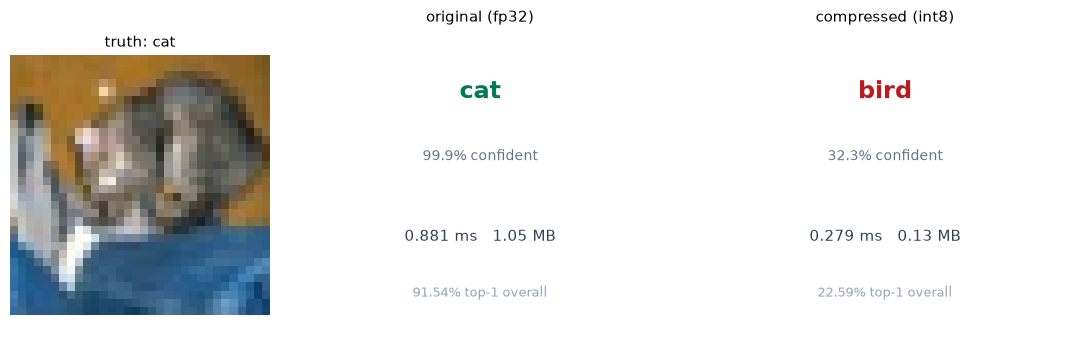

3.16x faster, 8.23x smaller, +68.95 pp accuracy


In [6]:
figure, axes = plt.subplots(1, 3, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 1.5, 1.5]})

axes[0].imshow(display)
axes[0].set_title(f"truth: {CLASSES[label]}", fontsize=11)
axes[0].axis("off")

for axis, name, path, predicted, confidence, measurement in [
    (axes[1], "original (fp32)", original_path, original_class, original_confidence, result.baseline),
    (axes[2], f"compressed ({result.final.precision})", compressed_path,
     compressed_class, compressed_confidence, result.final),
]:
    correct = predicted == label
    axis.text(0.5, 0.78, CLASSES[predicted], ha="center", fontsize=17,
              color="#047857" if correct else "#B91C1C", weight="bold")
    axis.text(0.5, 0.58, f"{confidence * 100:.1f}% confident", ha="center",
              fontsize=10, color="#64748B")
    axis.text(0.5, 0.32, f"{measurement.latency.median_ms:.3f} ms   "
                         f"{measurement.size_mb:.2f} MB", ha="center",
              fontsize=11, color="#334155")
    axis.text(0.5, 0.14, f"{measurement.accuracy * 100:.2f}% top-1 overall",
              ha="center", fontsize=9.5, color="#94A3B8")
    axis.set_title(name, fontsize=11)
    axis.axis("off")

plt.tight_layout()
plt.show()

print(f"{result.speedup:.2f}x faster, {result.size_reduction:.2f}x smaller, "
      f"{result.accuracy_drop:+.2f} pp accuracy")

## 4. Write the report

A standalone HTML file with the per-stage table, the Pareto plot, and the
per-layer sensitivity chart.

In [7]:
from compresskit.report import render
from compresskit.sensitivity import analyze

sensitivity = analyze(model, calib, batches=4)
print(sensitivity.summary(top=5))

path = render(result, "../artifacts/demo/report.html", sensitivity=sensitivity)
print(f"\nreport -> {path}")

per-layer 8-bit sensitivity (lower SQNR = more damage, worst first):
  layer1.2.conv1                     Conv        2,304  SQNR   45.64 dB  MSE 6.045e-04
  layer3.1.conv1                     Conv       36,864  SQNR   49.45 dB  MSE 2.514e-04
  conv1                              Conv          432  SQNR   49.69 dB  MSE 2.379e-04
  layer3.0.conv2                     Conv       36,864  SQNR   49.97 dB  MSE 2.234e-04
  layer2.0.conv1                     Conv        4,608  SQNR   50.00 dB  MSE 2.218e-04
  ... 17 more

report -> ../artifacts/demo/report.html
